# 59장 · 대화 문맥의 최근 턴과 요약 메모리

최근 턴을 자르는 방법은 오래된 발화를 제외하고, 요약은 여러 발화를 짧게 바꿉니다. 두 방법에서 어떤 사실이 사라지는지 비교합니다.

사용자가 ‘발표 장소를 기억하나요?’라고 물었습니다. 대화에는 회의실 B라는 말이 남아 있지만 최근 메시지 두 턴만 꺼내면 장소가 보이지 않습니다. 저장한 대화와 이번 모델 입력의 차이를 살펴봅니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## 슬라이싱으로 최근 발화 선택

한 턴은 한 질문과 그 질문에 대한 응답을 묶은 단위입니다. 여기서는 각 턴의 사용자 발화만 발췌했습니다. 실제 도구를 썼다면 도구 요청과 결과도 같은 턴에 묶어야 합니다.

**대화에서 유지할 최근 턴**　최근 두 발화에는 기한과 분량이 남고 장소와 언어는 빠집니다.

[웹 교재에서 열기](https://langchain-lecture.vercel.app/chapter59/index.html#practice-space)


### 셀 01 · 리스트 슬라이싱으로 최근 발화 선택

기존 수업 대화에서 최근 두 턴을 고릅니다. 장소를 담은 첫 발화가 남을까요?


In [1]:
turns = ["발표 장소는 회의실 B입니다.", "발표 언어는 한국어입니다.",
         "최종 제출 기한은 금요일 18시입니다.", "슬라이드는 5장으로 준비합니다."]
recent = turns[-2:]
print(recent)

['최종 제출 기한은 금요일 18시입니다.', '슬라이드는 5장으로 준비합니다.']


기한과 분량만 남습니다. 음수 인덱스로 만든 recent는 모델에 넘길 부분을 선택한 값입니다. 원래 turns에는 네 문장이 그대로 있습니다.


### 마지막 두 발화가 남기는 단서

<p>turns[-2:]에는 제출 기한과 슬라이드 수가 들어갑니다. 이 목록만 읽고 발표 장소를 물으면 회의실 B라는 단서를 찾을 수 없습니다.</p>


### 잘라 낸 입력과 그대로인 대화 기록

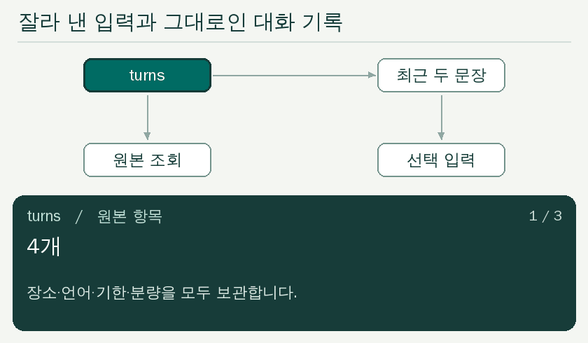

recent를 만든 뒤 turns[0]을 읽습니다. 어디에 장소가 남았는지를 따라가세요.


### 셀 02 · 저장된 이력에서 사실 복원

조금 전 만든 목록 대신 보관한 첫 발화를 읽습니다.


In [2]:
print(turns[0])

발표 장소는 회의실 B입니다.


‘회의실 B’가 보입니다. 기록을 잃어버린 경우와 모델에 일부만 보낸 경우를 같은 장애로 기록하면 고칠 곳을 찾기 어렵습니다.


### 원본 이력과 선택한 입력

<p>recent를 만든 뒤에도 turns[0]은 회의실 B라는 문장을 돌려줍니다. 원본에서 예전 발화를 지운 것이 아니라 모델에 전달할 후보를 마지막 두 항목으로 좁혔기 때문입니다.</p>


## 요약과 원문 기록의 정보 손실 대조

수업용 요약은 처음 세 턴을 읽고도 기한을 빠뜨렸습니다. 요약문에 출처 턴이 적혀 있는 것만으로 필요한 사실이 모두 보존됐다고 판단할 수 없습니다.

<!-- lesson-visual detail-summary -->
**같은 제출 기한이 요약과 최근 발화에 남는 방식**

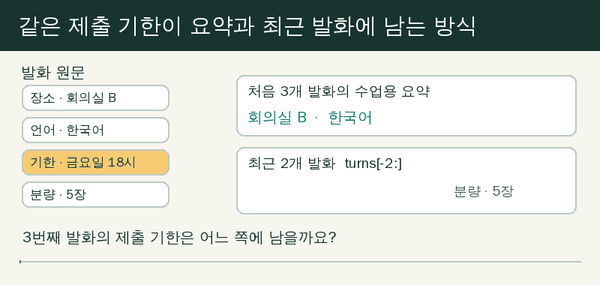

수업용 요약은 첫 세 발화 중 장소와 언어만 보존합니다. 세 번째 발화의 금요일 18시는 요약에서 빠지지만 최근 두 발화에는 남습니다. 같은 사실을 두 메모리 표현에서 찾아보세요.
<!-- /lesson-visual detail-summary -->


### 셀 03 · 요약에서 누락된 사실

금요일 18시라는 조건이 이 문장에 남았는지 확인하세요.


In [3]:
summary = "발표 장소는 회의실 B이며 발표 언어는 한국어입니다."
print("금요일 18시" in summary)

False


False가 나옵니다. 요약만 가진 모델은 제출 기한을 알 수 없습니다. 사용자가 기한을 물었다면 저장된 T3를 찾아 포함하거나 다시 확인해야 합니다.


### 요약이 잃어버린 사실

<p>요약에는 회의실 B와 한국어가 남았지만 금요일 18시는 빠졌습니다. 원본에서 문자열을 찾을 수 있다는 것과 이번 입력에 그 정보가 들어 있다는 것을 나눠 확인합니다.</p>


### 과제 04 · 요약과 최근 발화의 문맥 구성

요약 한 줄과 최근 발화 두 줄을 차례로 묶고 연결된 모델 입력을 줄 단위로 출력하세요.

‘금요일 18시’는 요약문에서 온 값이 아닙니다. 최근 발화 두 개 중 T3가 기한을 되살립니다. 뒤의 summary 비교는 최근 발화로 T4만 붙이므로 같은 요약을 써도 deadline이 비어 있습니다.


In [4]:
# summary와 recent를 묶어 줄바꿈으로 연결하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>context = [summary, *recent]
print(&#x27;\n&#x27;.join(context))</code></pre>
<p>실행 결과</p><pre><code>발표 장소는 회의실 B이며 발표 언어는 한국어입니다.
최종 제출 기한은 금요일 18시입니다.
슬라이드는 5장으로 준비합니다.</code></pre>
<p>요약이 장소와 언어를, 최근 두 문장이 기한과 분량을 제공합니다. 서비스에서는 현재 질문과 시스템 지시에 들어갈 자리도 예산에 포함합니다.</p>
</details>


### 요약과 최근 발화를 함께 쓰기

<p>장소·언어는 요약에서, 기한·슬라이드 수는 recent에서 확인할 수 있습니다. 두 입력을 이어 붙인 뒤 네 가지 질문에 필요한 단서가 실제로 있는지 찾아보세요.</p>


## 돌아보기

어떤 사실이 남는지는 대화 길이와 요약 내용에 달렸습니다. 새 주제의 대화에서도 남길 사용자 선호 한 가지를 고르고, 그 정보가 없을 때 무엇을 다시 물어볼지 정하세요.
